# 02 — Domain analysis: aviation supply and hotel demand

**Question:** which variables express the aviation-to-hotel mechanism clearly enough to support an interpretable simulator?

We follow the Goldenrod philosophy: domain reasoning → meaningful variables → observed relationships → a documented decision.
This notebook is the analysis stage. It does not train a production GAM, select a forecasting winner, or estimate causal route effects.

**Reading order:** research and hypotheses; measurement audit; markets and season; conversion and timing; conditional shapes; feature handoff.
Each section explains why a calculation matters and what it cannot establish. The last section generates conclusions from the actual results.

**Evidence boundary:** all demand relationships use 1 January 2023–31 December 2024. January–July 2025 remains available for later validation.
The unlabeled competition test period cannot supply an error metric. We inspect its column names only.

**Run:** select the project Python kernel (see README) and run all cells. Inputs are read only. Figures and tables are written to `reports/domain_analysis/`.
Source links are embedded so rerunning the analysis requires no network access. Python dependencies are recorded in `requirements-analysis.txt`.

## 1. Setup and evidence boundaries

The existing feature panel is an audit input. We rebuild analysis variables from the supplied spreadsheets,
so decisions such as zero-filling hotel rows or capping load factors do not silently become facts.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.nonparametric.smoothers_lowess import lowess
from IPython.display import display, Markdown

PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / 'dataset/01a - DCT Dataset').is_dir()), None)
assert PROJECT is not None, 'Run from the repository root or a directory inside it.'
DATA = PROJECT / 'dataset/01a - DCT Dataset'
OUT = PROJECT / 'reports/domain_analysis'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
START, END = pd.Timestamp('2023-01-01'), pd.Timestamp('2024-12-31')
DATES = pd.date_range(START, END)
RESEARCH_DATE = '2026-10-11'
SEED = 20261011
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .18, 'font.size': 10, 'figure.dpi': 110})
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_rows', 50)
ISSUES, CHECKS, TABLES = [], [], {}

def issue(name, finding, implication):
    ISSUES.append({'issue': name, 'finding': str(finding), 'implication': implication})

def check(name, condition):
    passed = bool(condition)
    CHECKS.append({'check': name, 'passed': passed})
    assert passed, name

def table(name, frame, show=True):
    frame = frame.copy()
    TABLES[name] = frame
    frame.to_csv(OUT / f'{name}.csv', index=False)
    if show:
        display(frame)
    return frame

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()

def ratio(numerator, denominator):
    return numerator / denominator.where(denominator > 0)

INPUT_PATHS = sorted(DATA.glob('*.xlsx')) + [PROJECT / 'data/features/panel.parquet',
    PROJECT / 'reference/bridge.csv', PROJECT / 'reference/events.csv',
    DATA / 'Data_Dictionary.pdf']
input_hashes = {str(p.relative_to(PROJECT)): hashlib.sha256(p.read_bytes()).hexdigest()
                for p in INPUT_PATHS}
print(f'Kernel Python: {platform.python_version()} | Analysis: {START.date()} to {END.date()}')
print(f'Project: {PROJECT}')

Kernel Python: 3.14.7 | Analysis: 2023-01-01 to 2024-12-31
Project: /home/srijan/Desktop/hack/ATRC_challenge


## 2. What domain research tells us to examine

These sources guide the questions; they do not supply fitted coefficients. Definitions, empirical findings,
and our hypotheses have different evidential status. The two research-paper entries are based on publisher
abstracts/highlights, not a replication or an independent assessment of their identification strategies.

In particular, UN tourism statistics distinguish nationality from residence and distinguish overnight visitors
from same-day visitors. Accommodation arrivals and nights are different measurements; their period totals
can support an average-stay indicator when coverage and definitions match. Neither definition alone resolves
the ambiguous `Guests` field in this specific extract. [UN IRTS, §§2.13, 2.19–2.20, 2.61, 6.32–6.34](https://unstats.un.org/unsd/publication/Seriesm/SeriesM_83rev1e.pdf)

In [2]:
sources = pd.DataFrame([
    ('UN_IRTS', 'Official statistical definitions', 'UN / UNWTO, International Recommendations for Tourism Statistics 2008',
     'https://unstats.un.org/unsd/publication/Seriesm/SeriesM_83rev1e.pdf',
     'Definitions: nationality differs from residence; arrivals differ from nights; an overnight transit visitor may be a tourist.',
     'Audit target units, same-day treatment, period guest-days per arrival, and country matching.', 'Definitions read; local column interpretation still needs confirmation.'),
    ('DCT_REPORTING', 'Official local reporting note', 'DCT Abu Dhabi, Hotel Performance Reports',
     'https://dct.gov.ae/en/who.we.are/reports.statistics.aspx',
     'DCT changed its hotel reporting system in January 2023 and cautions against historical comparisons.',
     'Use 2023 onward; distinguish a reporting change from demand growth.', 'Official note; no assumption that published totals cover the same 45 nationalities.'),
    ('IATA_METRICS', 'Official industry definitions', 'IATA, Understanding air traffic metrics',
     'https://www.iata.org/en/publications/newsletters/iata-knowledge-hub/understanding-air-traffic-metrics/',
     'Industry passenger load factor uses passenger-kilometres divided by seat-kilometres.',
     'Call our ratio passenger-to-seat ratio; do not equate an unweighted multi-route average with industry PLF.', 'Official explainer; distances absent from our extract.'),
    ('ETIHAD_STOPOVER', 'Official local programme evidence', 'Etihad Airways, Abu Dhabi Stopover programme growth (2 October 2024)',
     'https://www.etihad.com/en-at/news/etihad-airways-abu-dhabi-stopover-programme-achieves-exceptional-growth',
     'Connecting itineraries can include one or two complimentary hotel nights in Abu Dhabi.',
     'Treat zero hotel demand from all connecting passengers as an assumption; do not invent a stopover allocation.', 'Dated source within analysis period; dataset classification of stopovers is unknown.'),
    ('KOO_2017', 'Published empirical finding', 'Koo, Lim & Dobruszkes (2017), Causality in direct air services and tourism demand',
     'https://doi.org/10.1016/j.annals.2017.08.004',
     'The study reports context-dependent endogeneity between air service and visitor flows.',
     'Control for market, calendar, and trend; describe remaining relationships as associations.', 'Publisher abstract/highlights reviewed; no causal effect transferred to Abu Dhabi.'),
    ('KUOK_2024', 'Published empirical finding', 'Kuok, Koo & Lim (2024), Air transport capacity and tourism demand',
     'https://journals.sagepub.com/doi/10.1177/13548166231178355',
     'An Australian panel study reports positive, less-than-proportional capacity relationships and sensitivity to shared shocks.',
     'Examine nonlinear shapes, different markets, and calendar/trend adjustment.', 'Publisher abstract reviewed; Australian coefficients are not model priors here.'),
    ('LOCAL_DICTIONARY', 'Supplied dataset documentation', 'DCT competition Data Dictionary v1.0',
     '../../dataset/01a%20-%20DCT%20Dataset/Data_Dictionary.pdf',
     'Guests includes continuing stays; same-day placeholders can be suppressed or unavailable; passenger totals include infants.',
     'Check original cells, compare infant-excluded counts, retain target naming and missingness.', 'Read in full; metadata on flight grain/test columns conflicts with actual files.'),
], columns=['source_id', 'evidence_type', 'title', 'url', 'finding', 'analysis_implication', 'scope_limit'])
sources['reviewed_on'] = RESEARCH_DATE
table('sources', sources)
display(Markdown('### Linked reading list\n\n' + '\n'.join(
    f'- [{row.title}]({row.url}) — {row.scope_limit}' for row in sources.itertuples())))

hypotheses = pd.DataFrame([
    ('H1', 'Additional destination passengers accompany greater hotel demand within comparable markets and seasons.', 'Positive, possibly flattening', 'P2P versus Guests; raw and adjusted; 2023 versus 2024'),
    ('H2', 'Hotel demand reflects passengers from several previous days.', 'Positive carry-over with time decay', 'Trailing windows and assumed stay-weighted exposure'),
    ('H3', 'Conversion differs across markets and seasons.', 'Market-specific, seasonal', 'Monthly ratios, market plots, and year stability'),
    ('H4', 'Hotel demand remains positive without a matching direct flight.', 'Nonzero background demand possible', 'No-direct-market coverage and Guests'),
    ('H5', 'Frequency adds information beyond total seats.', 'Uncertain; requires evidence', 'Capacity-adjusted frequency association and collinearity'),
    ('H6', 'Higher connecting share means fewer destination passengers at fixed total passengers.', 'Arithmetic decrease in P2P; total hotel effect uncertain', 'Passenger identity; stopover and bridge limitations'),
], columns=['id', 'hypothesis', 'expected_shape', 'diagnostic'])
table('hypotheses', hypotheses)

,source_id,evidence_type,title,url,finding,analysis_implication,scope_limit,reviewed_on
0,UN_IRTS,Official statistical definitions,"UN / UNWTO, International Recommendations for Tourism Statistics 2008",https://unstats.un.org/unsd/publication/Seriesm/SeriesM_83rev1e.pdf,Definitions: nationality differs from residence; arrivals differ from nights; an overnight trans...,"Audit target units, same-day treatment, period guest-days per arrival, and country matching.",Definitions read; local column interpretation still needs confirmation.,2026-10-11
1,DCT_REPORTING,Official local reporting note,"DCT Abu Dhabi, Hotel Performance Reports",https://dct.gov.ae/en/who.we.are/reports.statistics.aspx,DCT changed its hotel reporting system in January 2023 and cautions against historical comparisons.,Use 2023 onward; distinguish a reporting change from demand growth.,Official note; no assumption that published totals cover the same 45 nationalities.,2026-10-11
2,IATA_METRICS,Official industry definitions,"IATA, Understanding air traffic metrics",https://www.iata.org/en/publications/newsletters/iata-knowledge-hub/understanding-air-traffic-me...,Industry passenger load factor uses passenger-kilometres divided by seat-kilometres.,Call our ratio passenger-to-seat ratio; do not equate an unweighted multi-route average with ind...,Official explainer; distances absent from our extract.,2026-10-11
3,ETIHAD_STOPOVER,Official local programme evidence,"Etihad Airways, Abu Dhabi Stopover programme growth (2 October 2024)",https://www.etihad.com/en-at/news/etihad-airways-abu-dhabi-stopover-programme-achieves-exception...,Connecting itineraries can include one or two complimentary hotel nights in Abu Dhabi.,Treat zero hotel demand from all connecting passengers as an assumption; do not invent a stopove...,Dated source within analysis period; dataset classification of stopovers is unknown.,2026-10-11
4,KOO_2017,Published empirical finding,"Koo, Lim & Dobruszkes (2017), Causality in direct air services and tourism demand",https://doi.org/10.1016/j.annals.2017.08.004,The study reports context-dependent endogeneity between air service and visitor flows.,"Control for market, calendar, and trend; describe remaining relationships as associations.",Publisher abstract/highlights reviewed; no causal effect transferred to Abu Dhabi.,2026-10-11
5,KUOK_2024,Published empirical finding,"Kuok, Koo & Lim (2024), Air transport capacity and tourism demand",https://journals.sagepub.com/doi/10.1177/13548166231178355,"An Australian panel study reports positive, less-than-proportional capacity relationships and se...","Examine nonlinear shapes, different markets, and calendar/trend adjustment.",Publisher abstract reviewed; Australian coefficients are not model priors here.,2026-10-11
6,LOCAL_DICTIONARY,Supplied dataset documentation,DCT competition Data Dictionary v1.0,../../dataset/01a%20-%20DCT%20Dataset/Data_Dictionary.pdf,Guests includes continuing stays; same-day placeholders can be suppressed or unavailable; passen...,"Check original cells, compare infant-excluded counts, retain target naming and missingness.",Read in full; metadata on flight grain/test columns conflicts with actual files.,2026-10-11


### Linked reading list

- [UN / UNWTO, International Recommendations for Tourism Statistics 2008](https://unstats.un.org/unsd/publication/Seriesm/SeriesM_83rev1e.pdf) — Definitions read; local column interpretation still needs confirmation.
- [DCT Abu Dhabi, Hotel Performance Reports](https://dct.gov.ae/en/who.we.are/reports.statistics.aspx) — Official note; no assumption that published totals cover the same 45 nationalities.
- [IATA, Understanding air traffic metrics](https://www.iata.org/en/publications/newsletters/iata-knowledge-hub/understanding-air-traffic-metrics/) — Official explainer; distances absent from our extract.
- [Etihad Airways, Abu Dhabi Stopover programme growth (2 October 2024)](https://www.etihad.com/en-at/news/etihad-airways-abu-dhabi-stopover-programme-achieves-exceptional-growth) — Dated source within analysis period; dataset classification of stopovers is unknown.
- [Koo, Lim & Dobruszkes (2017), Causality in direct air services and tourism demand](https://doi.org/10.1016/j.annals.2017.08.004) — Publisher abstract/highlights reviewed; no causal effect transferred to Abu Dhabi.
- [Kuok, Koo & Lim (2024), Air transport capacity and tourism demand](https://journals.sagepub.com/doi/10.1177/13548166231178355) — Publisher abstract reviewed; Australian coefficients are not model priors here.
- [DCT competition Data Dictionary v1.0](../../dataset/01a%20-%20DCT%20Dataset/Data_Dictionary.pdf) — Read in full; metadata on flight grain/test columns conflicts with actual files.

,id,hypothesis,expected_shape,diagnostic
0,H1,Additional destination passengers accompany greater hotel demand within comparable markets and s...,"Positive, possibly flattening",P2P versus Guests; raw and adjusted; 2023 versus 2024
1,H2,Hotel demand reflects passengers from several previous days.,Positive carry-over with time decay,Trailing windows and assumed stay-weighted exposure
2,H3,Conversion differs across markets and seasons.,"Market-specific, seasonal","Monthly ratios, market plots, and year stability"
3,H4,Hotel demand remains positive without a matching direct flight.,Nonzero background demand possible,No-direct-market coverage and Guests
4,H5,Frequency adds information beyond total seats.,Uncertain; requires evidence,Capacity-adjusted frequency association and collinearity
5,H6,Higher connecting share means fewer destination passengers at fixed total passengers.,Arithmetic decrease in P2P; total hotel effect uncertain,Passenger identity; stopover and bridge limitations


,id,hypothesis,expected_shape,diagnostic
0,H1,Additional destination passengers accompany greater hotel demand within comparable markets and s...,"Positive, possibly flattening",P2P versus Guests; raw and adjusted; 2023 versus 2024
1,H2,Hotel demand reflects passengers from several previous days.,Positive carry-over with time decay,Trailing windows and assumed stay-weighted exposure
2,H3,Conversion differs across markets and seasons.,"Market-specific, seasonal","Monthly ratios, market plots, and year stability"
3,H4,Hotel demand remains positive without a matching direct flight.,Nonzero background demand possible,No-direct-market coverage and Guests
4,H5,Frequency adds information beyond total seats.,Uncertain; requires evidence,Capacity-adjusted frequency association and collinearity
5,H6,Higher connecting share means fewer destination passengers at fixed total passengers.,Arithmetic decrease in P2P; total hotel effect uncertain,Passenger identity; stopover and bridge limitations


## 3. Audit the original measurements

We preserve blank and asterisk cells before numeric conversion. Missing hotel rows stay missing.
The absence of a flight record is interpreted as zero recorded service **only after** checking daily file coverage;
that still cannot prove the flight feed is complete. We retain this assumption in the issues table.

In [3]:
def read_hotel(filename, market_column=False):
    d = pd.read_excel(DATA / filename, keep_default_na=False)
    d['Date'] = pd.to_datetime(d['Date'])
    d = d.loc[d['Date'].between(START, END)].copy()
    if market_column:
        d['market'] = d['Nationality'].astype(str).str.strip().str.upper()
    for col in ['Guests', 'New Arrivals', 'Same-Day Guests']:
        raw = d[col].copy()
        d[col + '_blank'] = raw.astype(str).str.strip().eq('')
        d[col + '_suppressed'] = raw.astype(str).str.strip().eq('*')
        d[col] = pd.to_numeric(raw, errors='coerce')
    return d

hotel = read_hotel('data international_train.xlsx', True)
dom = read_hotel('data domestic_train.xlsx')
flight_all = pd.read_excel(DATA / 'flight_data.xlsx')
flight_all['Date'] = pd.to_datetime(flight_all['Date'])
grain = flight_all.groupby(flight_all['Date'].dt.year).agg(rows=('Date', 'size'), distinct_dates=('Date', 'nunique'))
table('flight_grain_inventory', grain.reset_index().rename(columns={'Date':'year'}))
fl = flight_all.loc[flight_all['Date'].between(START, END)].copy()
del flight_all
fl['market'] = fl['Departure Country Name'].str.strip().str.upper()
markets = sorted(hotel['market'].unique())
direct = set(fl['market'])
test_schema = {name: list(pd.read_excel(DATA / name, nrows=0).columns)
               for name in ['data international_test.xlsx', 'data domestic_test.xlsx']}
check('No target column in either supplied test schema', all('Guests' not in x for x in test_schema.values()))
check('Exactly 45 hotel markets and 33 matching flight origins in analysis window', len(markets)==45 and len(direct)==33)
check('All recorded flight origins have a same-name hotel market', direct.issubset(markets))
check('Hotel market/date keys are unique', not hotel.duplicated(['Date','market']).any())
check('Domestic dates are unique', not dom.duplicated('Date').any())
check('Flight route/date/airline keys are unique', not fl.duplicated(['Date','Departure City','Airline Name']).any())
check('Daily flight and domestic date coverage', set(fl.Date)==set(DATES) and set(dom.Date)==set(DATES))
check('Analysis hotel dates exclude tune/test', hotel.Date.min() >= START and hotel.Date.max() <= END)
table('source_inventory', pd.DataFrame([
    ('International hotel',len(hotel),hotel.Date.min(),hotel.Date.max()),
    ('Domestic hotel',len(dom),dom.Date.min(),dom.Date.max()),
    ('Flight operations',len(fl),fl.Date.min(),fl.Date.max())
], columns=['source','rows','first','last']))
issue('Dictionary versus extract', 'Dictionary describes monthly flights and a Guests field in test; observed files differ.',
      'Use observed grain/schema; retain dictionary as semantic guidance with documented conflicts.')

,year,rows,distinct_dates
0,2022,1213,12
1,2023,33349,365
2,2024,37607,366
3,2025,39126,365
4,2026,6313,59


,source,rows,first,last
0,International hotel,32862,2023-01-01,2024-12-31
1,Domestic hotel,731,2023-01-01,2024-12-31
2,Flight operations,70956,2023-01-01,2024-12-31


,definition,rows_above_1,rows_above_1_05,maximum
0,All passengers,5186,41,1.074713
1,Excluding infants,1929,2,1.051724


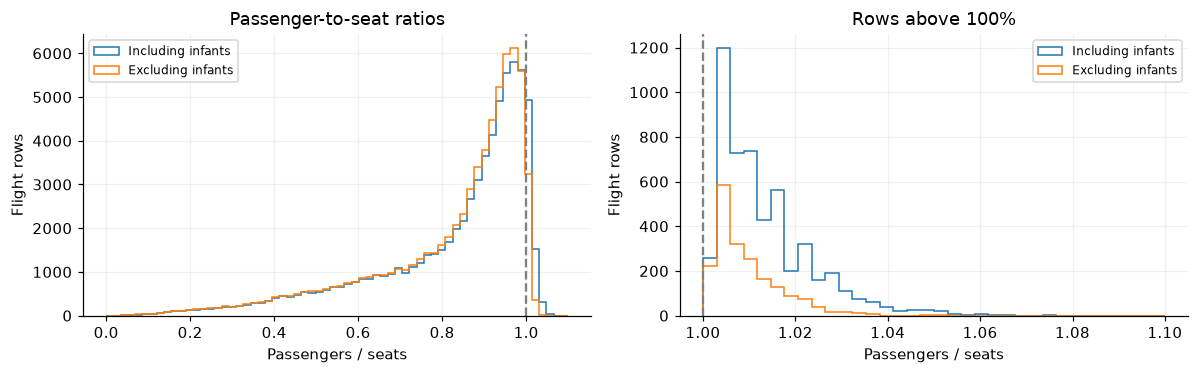

In [4]:
required_flight = ['Total Seats','Total PAX','Total PAX Excluding Infant','Total P2P','Total Transfer','Total Transit','Average Weekly Frequency','Load Factor']
check('Required flight measurements present', fl[required_flight].notna().all().all())
check('Seats positive and passenger segments nonnegative', (fl['Total Seats'] > 0).all() and (fl[['Total PAX','Total P2P','Total Transfer','Total Transit']] >= 0).all().all())
check('PAX equals P2P plus transfer plus transit', np.allclose(fl['Total PAX'],fl['Total P2P']+fl['Total Transfer']+fl['Total Transit']))
check('Reported LF equals total passengers / seats', np.allclose(fl['Load Factor'],fl['Total PAX']/fl['Total Seats']))
fl['flights_decoded'] = fl['Average Weekly Frequency'] * fl.Date.dt.days_in_month / 7
check('Decoded daily flight count is positive and integer-valued', (fl.flights_decoded > 0).all() and np.allclose(fl.flights_decoded,np.round(fl.flights_decoded)))
fl['flights_decoded'] = fl.flights_decoded.round().astype(int)
fl['lf_including_infants'] = fl['Total PAX'] / fl['Total Seats']
fl['lf_excluding_infants'] = fl['Total PAX Excluding Infant'] / fl['Total Seats']
fl['infant_count'] = fl['Total PAX'] - fl['Total PAX Excluding Infant']
check('Infant-excluded totals lie between zero and total PAX', (fl['Total PAX Excluding Infant'] >= 0).all() and (fl.infant_count >= 0).all())
lf_audit = pd.DataFrame([
    (label, int((fl[col]>1).sum()), int((fl[col]>1.05).sum()), fl[col].max())
    for label,col in [('All passengers','lf_including_infants'),('Excluding infants','lf_excluding_infants')]
], columns=['definition','rows_above_1','rows_above_1_05','maximum'])
table('load_factor_audit', lf_audit)
resolved_infant = int(((fl.lf_including_infants>1) & (fl.lf_excluding_infants<=1)).sum())
issue('Load factors above 100%', f'{resolved_infant:,} cases resolve when infants are excluded; {(fl.lf_excluding_infants>1).sum():,} remain.',
      'Keep both ratios and anomaly flags. Do not silently clip historical counts; seek clarification on remaining overshoot.')
fig, axes = plt.subplots(1,2,figsize=(11,3.5))
for label,col in [('Including infants','lf_including_infants'),('Excluding infants','lf_excluding_infants')]:
    axes[0].hist(fl[col], bins=np.linspace(0,1.1,65), histtype='step', label=label)
    axes[1].hist(fl.loc[fl[col]>1,col], bins=np.linspace(1,1.1,35),histtype='step',label=label)
axes[0].set(title='Passenger-to-seat ratios',xlabel='Passengers / seats',ylabel='Flight rows')
axes[1].set(title='Rows above 100%',xlabel='Passengers / seats',ylabel='Flight rows')
for ax in axes: ax.axvline(1,color='grey',ls='--'); ax.legend(fontsize=8)
savefig('01_load_factor_definitions')

**How to interpret this check.** The dataset explicitly includes infants in total PAX and provides an infant-excluded count.
An infant-related overshoot does not imply extra occupied seats. Remaining overshoots are unresolved discrepancies.
Aircraft frequency and gauge still produce seat supply arithmetically. Neither passenger ratio identifies the share who are visitors or hotel guests.

In [5]:
hotel_audit_rows = []
for stream,d in [('International',hotel),('Domestic',dom)]:
    for col in ['Guests','New Arrivals','Same-Day Guests']:
        hotel_audit_rows.append((stream,col,len(d),int(d[col].isna().sum()),int(d[col+'_blank'].sum()),
                                int(d[col+'_suppressed'].sum()),int(d[col].eq(0).sum())))
hotel_audit = table('hotel_missingness',pd.DataFrame(hotel_audit_rows,columns=['stream','column','rows','unknown','blank','asterisk','recorded_zero']))
check('No negative recorded hotel counts', not hotel[['Guests','New Arrivals','Same-Day Guests']].lt(0).any().any())
target_checks = pd.DataFrame([
    (stream,int((d['New Arrivals']>d.Guests).sum()),int((d['Same-Day Guests']>d.Guests).sum()),
     int((d.Guests==0).sum()),float(d['Same-Day Guests'].sum()/d.Guests.sum()))
    for stream,d in [('International',hotel),('Domestic',dom)]
],columns=['stream','arrivals_exceed_guests','same_day_exceeds_guests','zero_guests','observed_same_day_over_guests'])
table('target_semantics_checks',target_checks)
issue('Guests versus guest nights','Dictionary describes daily total guests and separately same-day guests, without defining whether they overlap.',
      'Use Guests (daily reported target) and guest-days (sum of daily target); do not silently relabel as overnight guest nights.')
issue('Blank same-day counts', f'{hotel["Same-Day Guests"].isna().sum():,} international rows have unknown same-day counts.',
      'Preserve unknown values. Guests minus known same-day counts is a sensitivity calculation, not a corrected target or a bound on true overnight stays.')
issue('Missing international hotel rows',len(DATES)*len(markets)-len(hotel),
      'Leave target and arrivals missing; do not assign zero from small neighboring values.')

,stream,column,rows,unknown,blank,asterisk,recorded_zero
0,International,Guests,32862,0,0,0,0
1,International,New Arrivals,32862,80,80,0,0
2,International,Same-Day Guests,32862,19302,19302,0,0
3,Domestic,Guests,731,0,0,0,0
4,Domestic,New Arrivals,731,0,0,0,0
5,Domestic,Same-Day Guests,731,0,0,0,0


,stream,arrivals_exceed_guests,same_day_exceeds_guests,zero_guests,observed_same_day_over_guests
0,International,0,0,0,0.003718
1,Domestic,0,0,0,0.009523


## 4. Build a transparent analysis table and audit the existing panel

Every row is one calendar day and one hotel nationality. Same-name flight origins are **proxies**, not observed nationality assignments.
All rolling features include today and earlier days only. Missing flight rows become zero **recorded** traffic; missing hotel observations remain unknown.

In [6]:
fm = fl.groupby(['Date','market']).agg(p2p=('Total P2P','sum'),pax=('Total PAX','sum'),
    pax_ex_infants=('Total PAX Excluding Infant','sum'),seats=('Total Seats','sum'),
    transfer=('Total Transfer','sum'),transit=('Total Transit','sum'),flights=('flights_decoded','sum'),
    n_airlines=('Airline Name','nunique'),n_cities=('Departure City','nunique'))
grid = pd.MultiIndex.from_product([DATES,markets],names=['Date','market'])
d = fm.reindex(grid)
d['flight_row_present'] = d.p2p.notna()
flight_cols = list(fm.columns)
d[flight_cols] = d[flight_cols].fillna(0)
d = d.join(hotel.set_index(['Date','market'])[['Guests','New Arrivals','Same-Day Guests']]).reset_index()
d = d.sort_values(['market','Date']).reset_index(drop=True)
d['hotel_row_present'] = pd.MultiIndex.from_frame(d[['Date','market']]).isin(pd.MultiIndex.from_frame(hotel[['Date','market']]))
d['has_same_name_origin'] = d.market.isin(direct)
d['year'],d['month'],d['dow'] = d.Date.dt.year,d.Date.dt.month,d.Date.dt.dayofweek
d['day_index'] = (d.Date-START).dt.days
d['ym'] = d.Date.dt.to_period('M')
g = d.groupby('market',sort=False)
for w in [1,3,7,14,28]:
    d[f'p2p_{w}d'] = g.p2p.transform(lambda v,w=w:v.rolling(w,min_periods=w).sum())
for col in ['seats','flights','pax','pax_ex_infants','transfer','transit']:
    d[f'{col}_7d'] = g[col].transform(lambda v:v.rolling(7,min_periods=7).sum())
d['lf_all_7d'] = ratio(d.pax_7d,d.seats_7d)
d['lf_ex_infants_7d'] = ratio(d.pax_ex_infants_7d,d.seats_7d)
d['transfer_share_7d'] = ratio(d.transfer_7d,d.pax_7d)
d['transit_share_7d'] = ratio(d.transit_7d,d.pax_7d)
d['seats_per_flight_7d'] = ratio(d.seats_7d,d.flights_7d)
d['origin_share_7d'] = ratio(d.p2p_7d,d.groupby('Date').p2p_7d.transform('sum'))
check('Analysis grid is unique and complete', len(d)==len(DATES)*len(markets) and not d.duplicated(['Date','market']).any())
check('Analysis flight totals reconcile to source', np.isclose(d.p2p.sum(),fl['Total P2P'].sum()) and np.isclose(d.seats.sum(),fl['Total Seats'].sum()))
check('Target totals and missingness survive grid completion', np.isclose(d.Guests.sum(),hotel.Guests.sum()) and d.Guests.count()==hotel.Guests.count())
issue('Zero recorded service convention',int((~d.flight_row_present).sum()),'Zero recorded flights is not proof of complete traffic coverage, nor proof of zero hotel demand.')

old = pd.read_parquet(PROJECT/'data/features/panel.parquet',filters=[('Date','>=',START),('Date','<=',END)])
old = old.set_index(['Date','market']).sort_index()
new = d.set_index(['Date','market']).sort_index()
check('Existing panel has expected analysis keys',old.index.equals(new.index))
check('Raw flight aggregation agrees with existing panel',np.allclose(old.p2p,new.p2p))
target_rewrites = new.Guests.isna() & old.Guests.notna()
check('Existing target matches raw wherever supplied',np.allclose(old.loc[new.Guests.notna(),'Guests'],new.loc[new.Guests.notna(),'Guests']))
share_complete = new.origin_share_7d.notna()
share_is_7d = np.allclose(old.loc[share_complete,'market_share_12m'],new.loc[share_complete,'origin_share_7d'])
table('existing_panel_audit',pd.DataFrame([
    ('Target values introduced on absent hotel rows',int(target_rewrites.sum()),'Use original unknowns in this notebook'),
    ('market_share_12m actually equals trailing 7-day share',bool(share_is_7d),'Use the accurate name origin_share_7d'),
    ('Existing target-derived history features','season_index, elasticity_tier, capture_rate_hist, stay_length_hist','Exclude from explanatory predictor diagnostics'),
],columns=['check','finding','analysis_action']))
issue('Existing panel target imputation',int(target_rewrites.sum()),'Analysis preserves raw missing target observations; no edits to the cleaning notebook or existing panel.')
issue('Misnamed market_share_12m',bool(share_is_7d),'It is a 7-day origin share; use an accurately named recomputation.')

,check,finding,analysis_action
0,Target values introduced on absent hotel rows,29,Use original unknowns in this notebook
1,market_share_12m actually equals trailing 7-day share,True,Use the accurate name origin_share_7d
2,Existing target-derived history features,"season_index, elasticity_tier, capture_rate_hist, stay_length_hist",Exclude from explanatory predictor diagnostics


## 5. Market coverage, scale, and season

Flight origin is the last recorded departure country; nationality is a person's passport classification.
A nationality without a same-name origin may still have substantial hotel demand. Neither an identity bridge
nor allocations from transfer flows are identifiable from these aggregates alone.

Seasonal comparisons use **mean daily** target counts rather than monthly totals, so February is not penalized for being shorter.
Each year is normalized separately to reduce the influence of overall growth. The two years remain visible.

,market,guest_days,guests_days_known,hotel_arrivals,arrivals_days_known,p2p,seats,transfer,pax,flight_days,has_same_name_origin,target_coverage,connecting_share
15,INDIA,1861134.0,731,570832.0,731,3296948.0,6441778.0,2389788.0,5686765.0,731,True,1.0,0.420237
34,RUSSIAN FEDERATION,1608371.0,731,321682.0,731,212625.0,463613.0,172549.0,385174.0,731,True,1.0,0.447977
42,UNITED KINGDOM,1592906.0,731,328754.0,731,345697.0,1380272.0,878724.0,1224421.0,731,True,1.0,0.717665
8,CHINA,835327.0,731,406117.0,731,66043.0,312663.0,155875.0,221918.0,634,True,1.0,0.702399
14,GERMANY,787326.0,731,156474.0,731,166267.0,668101.0,421944.0,588211.0,730,True,1.0,0.717334
43,UNITED STATES OF AMERICA,747749.0,731,189717.0,731,94070.0,960732.0,770436.0,864506.0,731,True,1.0,0.891186
35,SAUDI ARABIA,739308.0,731,299783.0,731,779268.0,1970143.0,743025.0,1522293.0,731,True,1.0,0.488096
22,KUWAIT,532061.0,731,160937.0,731,280969.0,654557.0,168616.0,449585.0,731,True,1.0,0.375048
13,FRANCE,514131.0,731,143383.0,731,126110.0,387341.0,215322.0,341432.0,724,True,1.0,0.630644
11,EGYPT,486034.0,731,102173.0,731,868295.0,1197504.0,156753.0,1025048.0,731,True,1.0,0.152923


,market,guest_days,guests_days_known,hotel_arrivals,arrivals_days_known,p2p,seats,transfer,pax,flight_days,has_same_name_origin,target_coverage,connecting_share
1,AUSTRALIA,197607.0,731,58495.0,731,0.0,0.0,0.0,0.0,0,False,1.000000,NaN
29,PAKISTAN,180104.0,731,59904.0,731,0.0,0.0,0.0,0.0,0,False,1.000000,NaN
33,ROMANIA,160896.0,731,47710.0,731,0.0,0.0,0.0,0.0,0,False,1.000000,NaN
36,SOUTH AFRICA,152298.0,731,35281.0,731,0.0,0.0,0.0,0.0,0,False,1.000000,NaN
6,BRAZIL,95317.0,731,22941.0,731,0.0,0.0,0.0,0.0,0,False,1.000000,NaN
25,MOROCCO,92133.0,731,25939.0,731,0.0,0.0,0.0,0.0,0,False,1.000000,NaN
9,CZECHIA,75401.0,731,21245.0,729,0.0,0.0,0.0,0.0,0,False,1.000000,NaN
39,SWEDEN,68516.0,731,13734.0,729,0.0,0.0,0.0,0.0,0,False,1.000000,NaN
24,MEXICO,44306.0,731,11744.0,724,0.0,0.0,0.0,0.0,0,False,1.000000,NaN
10,DENMARK,37252.0,722,8680.0,709,0.0,0.0,0.0,0.0,0,False,0.987688,NaN


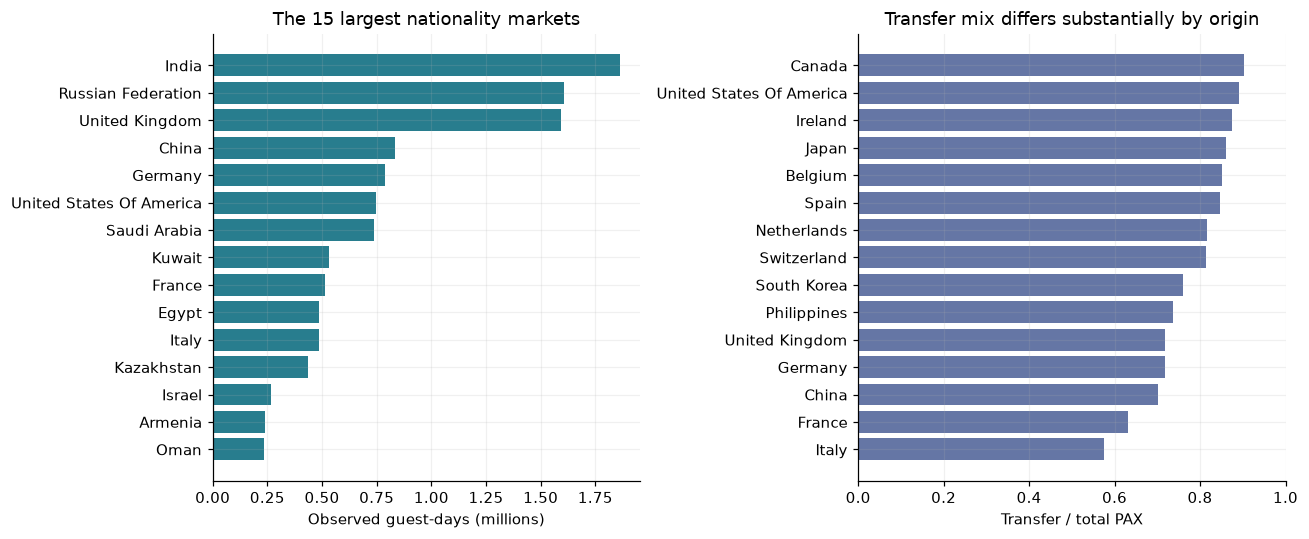

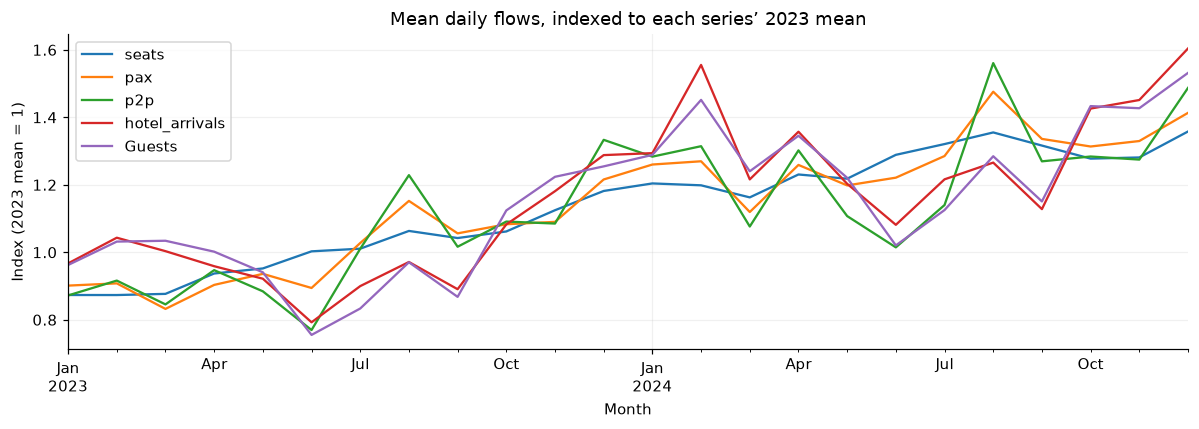

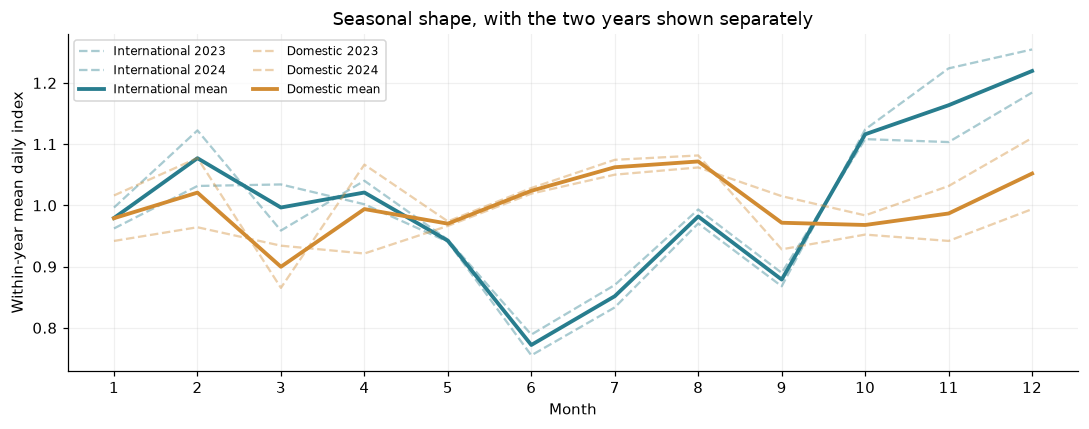

,year,month,Guests,dom_guests
0,2023,1,0.962326,0.941922
1,2023,2,1.031702,0.964289
2,2023,3,1.034198,0.934185
3,2023,4,1.001831,0.921380
4,2023,5,0.940656,0.966446
5,2023,6,0.755095,1.019222
6,2023,7,0.833391,1.050159
7,2023,8,0.970438,1.061937
8,2023,9,0.867895,1.015077
9,2023,10,1.124068,0.983700


,year,month,Guests,dom_guests
0,2023,1,0.962326,0.941922
1,2023,2,1.031702,0.964289
2,2023,3,1.034198,0.934185
3,2023,4,1.001831,0.921380
4,2023,5,0.940656,0.966446
5,2023,6,0.755095,1.019222
6,2023,7,0.833391,1.050159
7,2023,8,0.970438,1.061937
8,2023,9,0.867895,1.015077
9,2023,10,1.124068,0.983700


In [7]:
market_summary = d.groupby('market').agg(guest_days=('Guests','sum'),guests_days_known=('Guests','count'),
    hotel_arrivals=('New Arrivals','sum'),arrivals_days_known=('New Arrivals','count'),
    p2p=('p2p','sum'),seats=('seats','sum'),transfer=('transfer','sum'),pax=('pax','sum'),
    flight_days=('flight_row_present','sum'),has_same_name_origin=('has_same_name_origin','first')).reset_index()
market_summary['target_coverage'] = market_summary.guests_days_known/len(DATES)
market_summary['connecting_share'] = ratio(market_summary.transfer,market_summary.pax)
market_summary = market_summary.sort_values('guest_days',ascending=False)
table('market_coverage',market_summary,show=False)
display(market_summary.head(12))
table('markets_without_same_name_origin',market_summary.loc[~market_summary.has_same_name_origin])
no_origin_share = market_summary.loc[~market_summary.has_same_name_origin,'guest_days'].sum()/market_summary.guest_days.sum()
issue('Unidentified country bridge',f'{no_origin_share:.1%} of observed international guest-days belong to the 12 nationalities without a same-name origin.',
      'These are background-demand examples, not zero-demand markets. New-route response needs separate evidence and explicit assumptions.')

fig,axes=plt.subplots(1,2,figsize=(12,5))
top=market_summary.head(15).sort_values('guest_days')
axes[0].barh(top.market.str.title(),top.guest_days/1e6,color=np.where(top.has_same_name_origin,'#287d8e','#d18b32'))
axes[0].set(xlabel='Observed guest-days (millions)',title='The 15 largest nationality markets')
top2=market_summary[market_summary.has_same_name_origin].sort_values('connecting_share').tail(15)
axes[1].barh(top2.market.str.title(),top2.connecting_share,color='#6576a5')
axes[1].set(xlabel='Transfer / total PAX',title='Transfer mix differs substantially by origin',xlim=(0,1))
savefig('02_market_coverage')

daily=d.groupby('Date').agg(Guests=('Guests','sum'),hotel_arrivals=('New Arrivals','sum'),
    target_markets=('Guests','count'),p2p=('p2p','sum'),pax=('pax','sum'),seats=('seats','sum'))
daily=daily.join(dom.set_index('Date')[['Guests','New Arrivals']].rename(columns={'Guests':'dom_guests','New Arrivals':'dom_arrivals'}))
monthly_overview=daily.resample('MS').mean()
cols=['seats','pax','p2p','hotel_arrivals','Guests']
indexed=monthly_overview[cols]/monthly_overview.loc['2023',cols].mean()
indexed.plot(title='Mean daily flows, indexed to each series’ 2023 mean',ylabel='Index (2023 mean = 1)',xlabel='Month')
savefig('03_monthly_flows')
table('daily_aggregate_coverage',daily.reset_index(),show=False)

season=daily[['Guests','dom_guests']].copy()
season['year'],season['month']=season.index.year,season.index.month
season=season.groupby(['year','month'])[['Guests','dom_guests']].mean()
season=season/season.groupby(level='year').transform('mean')
fig,ax=plt.subplots(figsize=(10,4))
for col,label,color in [('Guests','International','#287d8e'),('dom_guests','Domestic','#d18b32')]:
    for yr in [2023,2024]: ax.plot(range(1,13),season.loc[yr,col],color=color,alpha=.4,ls='--',label=f'{label} {yr}')
    ax.plot(range(1,13),season[col].groupby('month').mean(),color=color,lw=2.5,label=f'{label} mean')
ax.set(xticks=range(1,13),xlabel='Month',ylabel='Within-year mean daily index',title='Seasonal shape, with the two years shown separately')
ax.legend(ncol=2,fontsize=8)
savefig('04_seasonality')
table('seasonality',season.reset_index())

**Coverage limitation:** aggregate plots sum observed targets. Missing nationality-days are counted in the accompanying
coverage table; they are not silently imputed. Domestic demand is described separately and is not assigned an aviation response.
We do not equate the extract with all hotels or all nationalities in published DCT totals; matching geography and coverage have not been established.

## 6. Conversion ratios: useful diagnostics, not identified probabilities

We calculate two period ratios only for months with **all days observed in the required hotel columns**:

- Hotel check-ins / same-name origin P2P: a cross-dataset comparison, not a hotel-capture probability.
- Sum of `Guests` / sum of hotel check-ins: reported guest-days per arrival, not automatically verified length of stay.

The second is a ratio of period sums, not an average of daily ratios. Boundary-crossing stays and unknown same-day treatment still matter.
The dictionary does not establish whether same-day guests are already inside `Guests` or `New Arrivals`; no subtraction is treated as truth.

,market,median_arrivals_per_p2p,median_guest_days_per_arrival,valid_conversion_months,valid_stay_months
0,ARMENIA,0.232021,5.174259,21,21
1,AUSTRALIA,NaN,3.325526,0,24
2,AUSTRIA,0.196303,4.454197,24,24
3,AZERBAIJAN,0.067631,3.695880,22,22
4,BAHRAIN,0.157626,2.988090,24,24
5,BELGIUM,1.098096,3.873727,24,24
6,BRAZIL,NaN,4.144031,0,24
7,CANADA,2.691686,3.989761,24,24
8,CHINA,6.152008,2.061662,24,24
9,CZECHIA,NaN,3.420786,0,22


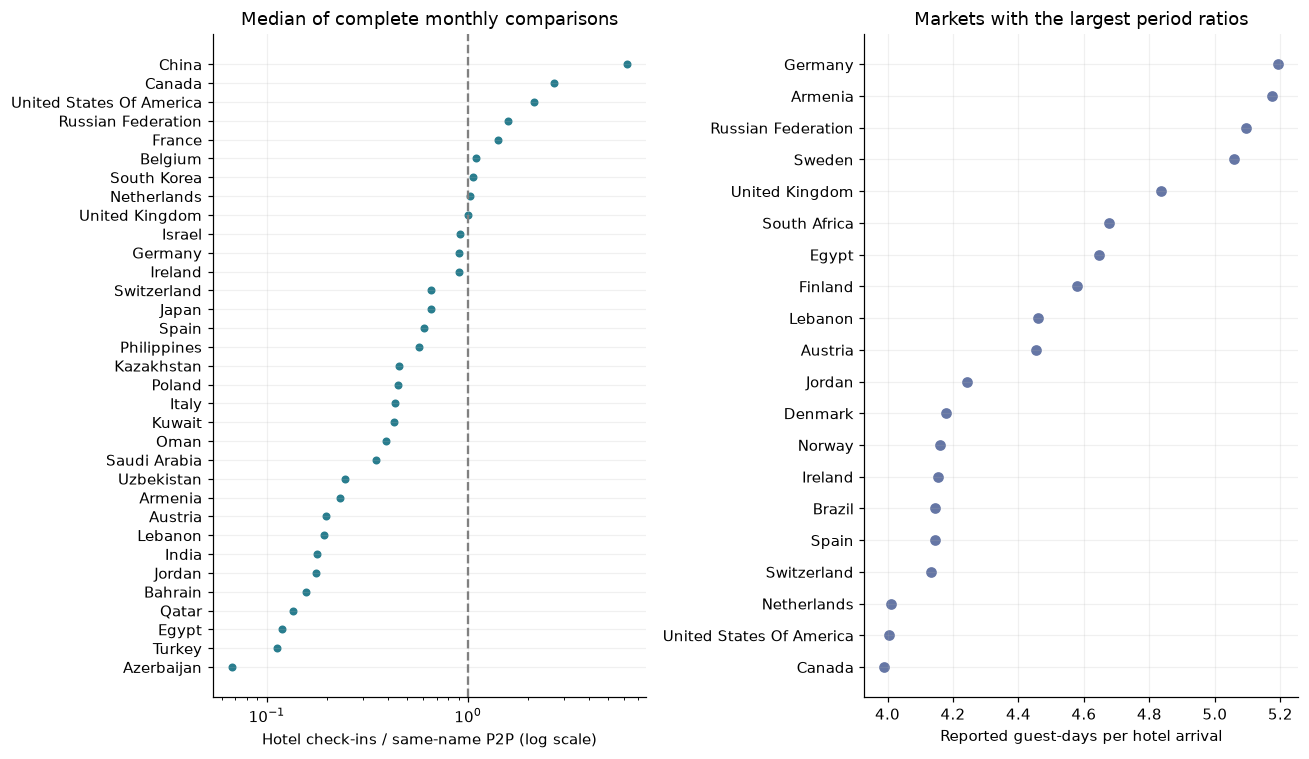

In [8]:
monthly=d.groupby(['market','ym']).agg(Guests=('Guests',lambda x:x.sum(min_count=1)),
    arrivals=('New Arrivals',lambda x:x.sum(min_count=1)),same_day=('Same-Day Guests',lambda x:x.sum(min_count=1)),
    target_days=('Guests','count'),arrival_days=('New Arrivals','count'),same_day_known_days=('Same-Day Guests','count'),
    days=('Date','size'),p2p=('p2p','sum'),seats=('seats','sum'),flights=('flights','sum')).reset_index()
monthly['arrivals_complete']=monthly.arrival_days.eq(monthly.days)
monthly['target_complete']=monthly.target_days.eq(monthly.days)
monthly['arrivals_per_p2p']=ratio(monthly.arrivals,monthly.p2p).where(monthly.arrivals_complete)
monthly['guest_days_per_arrival']=ratio(monthly.Guests,monthly.arrivals).where(monthly.arrivals_complete & monthly.target_complete)
# Subtract only observed same-day counts as a sensitivity scenario. Unknown cells remain unknown in the raw data.
monthly['guest_days_per_arrival_minus_known_same_day']=ratio(monthly.Guests-monthly.same_day.fillna(0),monthly.arrivals).where(monthly.arrivals_complete & monthly.target_complete)
table('monthly_conversion',monthly,show=False)
conv=monthly.groupby('market').agg(median_arrivals_per_p2p=('arrivals_per_p2p','median'),
    median_guest_days_per_arrival=('guest_days_per_arrival','median'),valid_conversion_months=('arrivals_per_p2p','count'),
    valid_stay_months=('guest_days_per_arrival','count')).reset_index()
table('conversion_by_market',conv)
valid_conv=monthly.arrivals_per_p2p.dropna()
issue('Conversion ratio exceeds probability bounds',f'{(valid_conv>1).sum()} / {len(valid_conv)} complete origin-months exceed one.',
      'Do not clamp or call this an individual capture probability; departure country, nationality, and travel coverage differ.')
fig,axes=plt.subplots(1,2,figsize=(12,7))
c=conv.dropna(subset=['median_arrivals_per_p2p']).sort_values('median_arrivals_per_p2p')
axes[0].scatter(c.median_arrivals_per_p2p,c.market.str.title(),color='#287d8e',s=18)
axes[0].axvline(1,color='grey',ls='--'); axes[0].set(xscale='log',xlabel='Hotel check-ins / same-name P2P (log scale)',title='Median of complete monthly comparisons')
c2=conv.sort_values('median_guest_days_per_arrival').tail(20)
axes[1].scatter(c2.median_guest_days_per_arrival,c2.market.str.title(),color='#6576a5')
axes[1].set(xlabel='Reported guest-days per hotel arrival',title='Markets with the largest period ratios')
savefig('05_conversion_ratios')

## 7. Timing: passengers arrive once; hotel presence persists

A trailing sum counts recent destination passengers equally. A stay-weighted exposure assumes a decreasing probability
that a person remains present. We compare both; we cannot identify an actual stay distribution from aggregate counts alone.

For an assumed geometric stay with mean (L) days, use weights (w_k=(1-1/L)^k) for (k=0,ldots,27).
The exposure is (sum_k w_k P2P_{t-k}). These are assumptions about carry-over, not fitted guest-night predictions.
Means of 2, 4, and 7 days probe sensitivity. The truncated weight mass is reported, and the same first 27 days are excluded
from every timing comparison. No 2022 monthly flight total is treated as a daily warm-up observation.

,assumed_mean_days,retained_weight_sum,omitted_fraction_of_infinite_weight_mass
0,2,2.000000,3.725290e-09
1,4,3.998730,3.174793e-04
2,7,6.906548,1.335027e-02


,feature,year,markets,median_raw,median_adjusted,fraction_positive
0,p2p_14d,2023,33,0.443346,0.396002,1.000000
1,p2p_14d,2024,33,0.391583,0.334561,0.969697
2,p2p_1d,2023,33,0.232655,0.202303,1.000000
3,p2p_1d,2024,33,0.196261,0.164061,1.000000
4,p2p_28d,2023,33,0.378695,0.265709,0.969697
5,p2p_28d,2024,33,0.344080,0.254595,0.969697
6,p2p_3d,2023,33,0.408165,0.377269,1.000000
7,p2p_3d,2024,33,0.363936,0.331246,1.000000
8,p2p_7d,2023,33,0.472732,0.444144,1.000000
9,p2p_7d,2024,33,0.420382,0.452757,1.000000


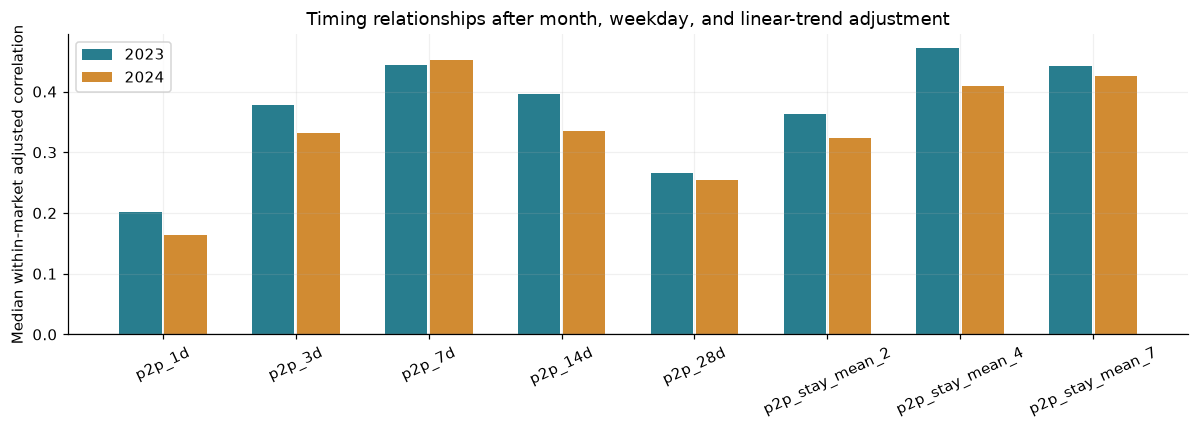

In [9]:
kernel_rows=[]
for mean in [2,4,7]:
    weights=(1-1/mean)**np.arange(28)
    col=f'p2p_stay_mean_{mean}'
    d[col]=d.groupby('market').p2p.transform(lambda v,w=weights:np.convolve(v.to_numpy(),w,mode='full')[:len(v)])
    d.loc[d.day_index<27,col]=np.nan
    kernel_rows.append((mean,float(weights.sum()),float((1-1/mean)**28)))
table('assumed_stay_kernels',pd.DataFrame(kernel_rows,columns=['assumed_mean_days','retained_weight_sum','omitted_fraction_of_infinite_weight_mass']))
timing_features=[f'p2p_{w}d' for w in [1,3,7,14,28]]+[f'p2p_stay_mean_{m}' for m in [2,4,7]]
timing=d.loc[d.day_index>=27].copy()

def nuisance_matrix(frame):
    # Within-market controls. Linear trend does not claim to remove every shared demand shock.
    category=frame[['month','dow']].astype(str)
    dummy=pd.get_dummies(category,drop_first=True,dtype=float)
    return np.column_stack([np.ones(len(frame)),frame.day_index.to_numpy()/365.25,dummy.to_numpy()])

def residualize(frame, cols):
    z=nuisance_matrix(frame)
    vals=frame[cols].to_numpy(float)
    return vals-z@np.linalg.lstsq(z,vals,rcond=None)[0]

def safe_corr(a,b):
    a,b=np.asarray(a),np.asarray(b)
    ok=np.isfinite(a)&np.isfinite(b)
    if ok.sum()<30 or np.std(a[ok])<1e-10 or np.std(b[ok])<1e-10: return np.nan
    return float(np.corrcoef(a[ok],b[ok])[0,1])

timing_results=[]
for market,grp in timing[timing.has_same_name_origin].groupby('market'):
    for year in [2023,2024]:
        a=grp.loc[grp.year.eq(year),['Date','month','dow','day_index','Guests',*timing_features]].dropna().copy()
        logcols=['Guests',*timing_features]
        logged=a.copy(); logged[logcols]=np.log1p(a[logcols])
        res=residualize(logged,logcols)
        for j,feature in enumerate(timing_features,1):
            timing_results.append((market,year,feature,len(a),safe_corr(logged[feature],logged.Guests),safe_corr(res[:,j],res[:,0])))
timing_results=pd.DataFrame(timing_results,columns=['market','year','feature','n','raw_log_correlation','adjusted_log_correlation'])
table('timing_by_market_year',timing_results,show=False)
timing_summary=timing_results.groupby(['feature','year']).agg(markets=('adjusted_log_correlation','count'),
    median_raw=('raw_log_correlation','median'),median_adjusted=('adjusted_log_correlation','median'),
    fraction_positive=('adjusted_log_correlation',lambda s:(s.dropna()>0).mean())).reset_index()
table('timing_summary',timing_summary)
fig,ax=plt.subplots(figsize=(11,4))
order=timing_features
for year,offset,color in [(2023,-.17,'#287d8e'),(2024,.17,'#d18b32')]:
    val=timing_summary[timing_summary.year.eq(year)].set_index('feature').reindex(order)
    ax.bar(np.arange(len(order))+offset,val.median_adjusted,.32,label=str(year),color=color)
ax.axhline(0,color='grey',lw=.8)
ax.set(xticks=np.arange(len(order)),xticklabels=order,ylabel='Median within-market adjusted correlation',
       title='Timing relationships after month, weekday, and linear-trend adjustment')
ax.tick_params(axis='x',rotation=25); ax.legend()
savefig('06_passenger_timing')

**What this controls for:** calendar and linear trend are fitted separately within each market-year.
Correlations therefore compare variation within a market, rather than rewarding large markets for being large.
Removing trend can also remove genuine aviation-related growth; raw and adjusted results are shown together.
The correlations are diagnostics, not out-of-sample scores, causal effects, or guarantees of monotonicity.

Next we examine the **hotel-side** timing using supplied hotel check-ins. This is descriptive only: those check-ins
are not known inputs for a hypothetical new route. It must remain separate from a flight-driven simulator feature.

,feature,year,median_adjusted,markets
0,arrivals_14d,2023,0.579271,45
1,arrivals_14d,2024,0.563849,45
2,arrivals_1d,2023,0.672925,45
3,arrivals_1d,2024,0.679161,45
4,arrivals_28d,2023,0.385867,45
5,arrivals_28d,2024,0.390361,45
6,arrivals_3d,2023,0.838754,45
7,arrivals_3d,2024,0.818737,45
8,arrivals_7d,2023,0.761240,45
9,arrivals_7d,2024,0.756559,45


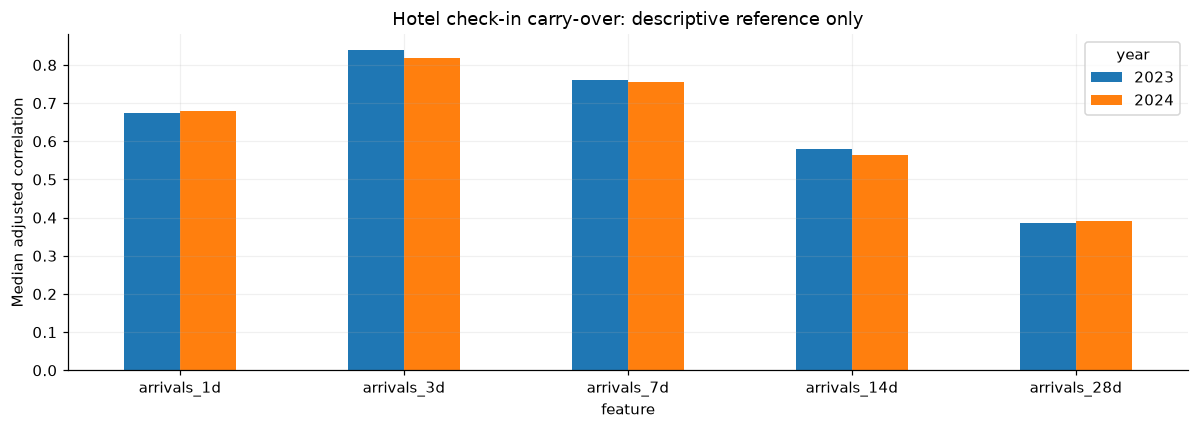

In [10]:
hotel_timing=[]
for market,grp in d.groupby('market'):
    a=grp.sort_values('Date').copy()
    arrival_cols=[]
    for w in [1,3,7,14,28]:
        col=f'arrivals_{w}d'; arrival_cols.append(col)
        a[col]=a['New Arrivals'].rolling(w,min_periods=w).sum()
    # A single complete-case set for all windows; unknown check-ins are never replaced by zero.
    for yr in [2023,2024]:
        b=a.loc[a.year.eq(yr)&a.day_index.ge(27)].dropna(subset=['Guests',*arrival_cols]).copy()
        if len(b)<60: continue
        cols=['Guests',*arrival_cols]; b[cols]=np.log1p(b[cols]); res=residualize(b,cols)
        for j,col in enumerate(arrival_cols,1):
            hotel_timing.append((market,yr,col,len(b),safe_corr(b[col],b.Guests),safe_corr(res[:,j],res[:,0])))
hotel_timing=pd.DataFrame(hotel_timing,columns=['market','year','feature','n','raw_log_correlation','adjusted_log_correlation'])
table('hotel_checkin_timing',hotel_timing,show=False)
hotel_timing_summary=hotel_timing.groupby(['feature','year']).agg(median_adjusted=('adjusted_log_correlation','median'),markets=('market','nunique')).reset_index()
table('hotel_checkin_timing_summary',hotel_timing_summary)
hotel_timing_summary.pivot(index='feature',columns='year',values='median_adjusted').reindex([f'arrivals_{w}d' for w in [1,3,7,14,28]]).plot.bar(
    ylabel='Median adjusted correlation',title='Hotel check-in carry-over: descriptive reference only',rot=0)
savefig('07_hotel_checkin_timing')

## 8. Inspect shapes without manufacturing monotonicity

For a common diagnostic we use the predeclared seven-day P2P exposure, rather than select a window because it produces a preferred curve.
First compare pooled log counts, market-centered log counts, and fully adjusted log counts. Then inspect individual markets.

LOWESS uses a fixed smoothing fraction of 0.5. Quantile bins show means; point size and the count range indicate support.
Exact per-bin counts are exported alongside the plots. Duplicate cut points are dropped.
These curves are exploratory and unconstrained. A slope or correlation does not certify that a relationship is everywhere monotonic.

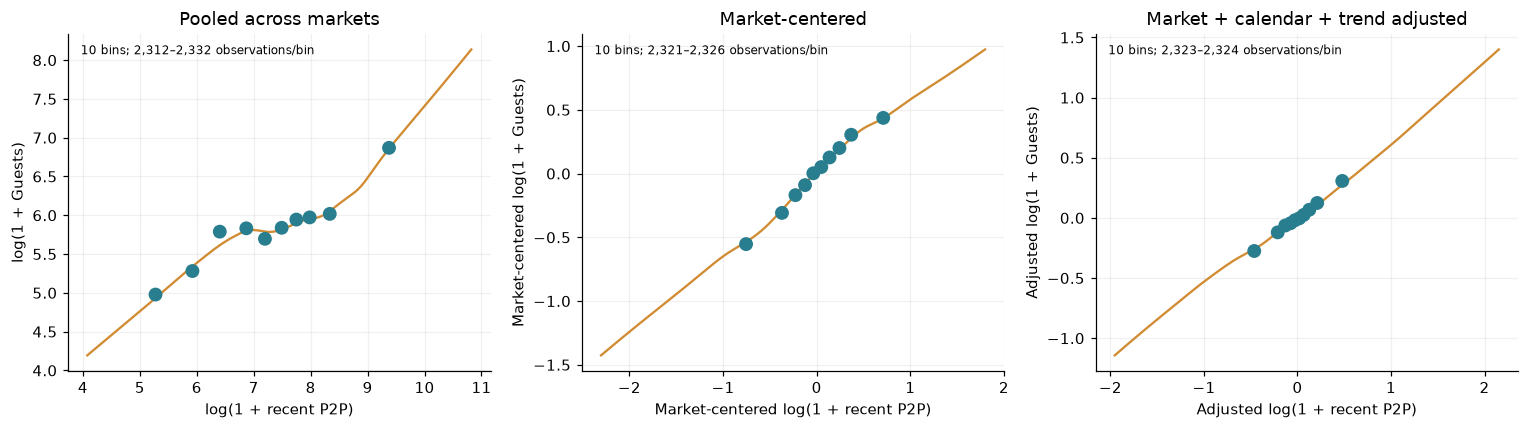

,comparison,correlation
0,Pooled log counts,0.456095
1,Market-centered log counts,0.539297
2,Calendar/trend-adjusted within market,0.468895


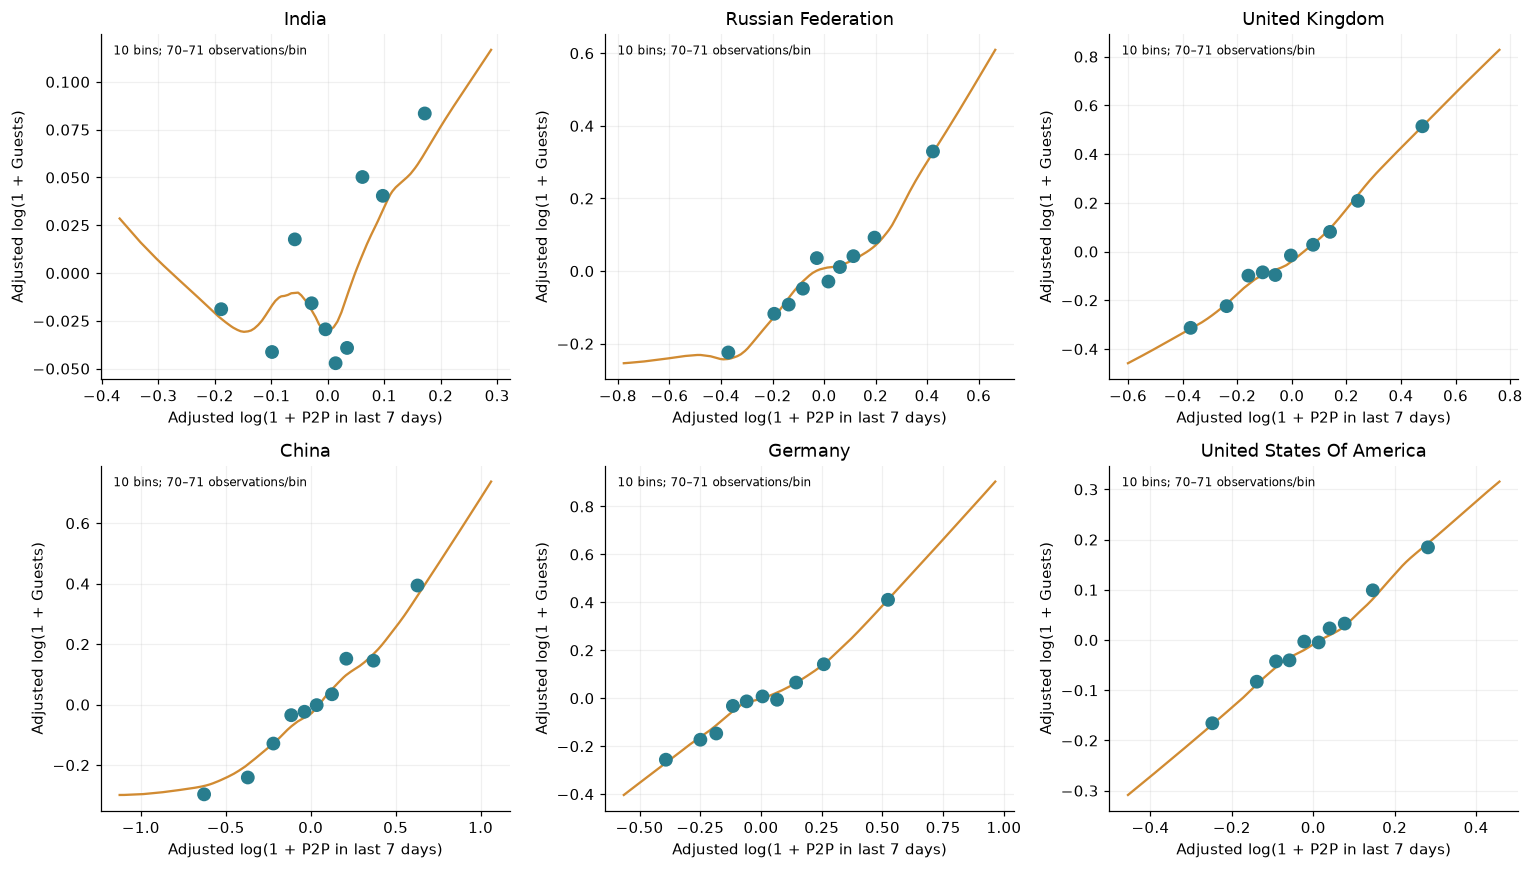

In [11]:
shape=d.loc[d.day_index.ge(27)&d.has_same_name_origin].dropna(subset=['Guests','p2p_7d']).copy()
shape['lx'],shape['ly']=np.log1p(shape.p2p_7d),np.log1p(shape.Guests)
shape['within_x']=shape.lx-shape.groupby('market').lx.transform('mean')
shape['within_y']=shape.ly-shape.groupby('market').ly.transform('mean')
shape['adjusted_x'],shape['adjusted_y']=np.nan,np.nan
for market,idx in shape.groupby('market').groups.items():
    r=residualize(shape.loc[idx],['lx','ly'])
    shape.loc[idx,['adjusted_x','adjusted_y']]=r

def binned_plot(ax,frame,x,y,title):
    a=frame[[x,y]].dropna().copy()
    if a[x].nunique()<3:
        ax.text(.5,.5,'Insufficient variation',ha='center',transform=ax.transAxes); return pd.DataFrame()
    a['bin']=pd.qcut(a[x],q=min(10,a[x].nunique()),duplicates='drop')
    b=a.groupby('bin',observed=True).agg(x=(x,'mean'),y=(y,'mean'),n=(y,'size')).reset_index(drop=True)
    ax.scatter(b.x,b.y,s=25+40*b.n/b.n.max(),color='#287d8e',zorder=3)
    ax.text(.03,.97,f'{len(b)} bins; {b.n.min():,}–{b.n.max():,} observations/bin',
            va='top',transform=ax.transAxes,fontsize=8)
    # Average ties before drawing LOWESS; no target transformation is fed to a predictive model.
    smooth=lowess(a[y],a[x],frac=.5,it=1,return_sorted=True,delta=.01*max(a[x].max()-a[x].min(),1e-6))
    ax.plot(smooth[:,0],smooth[:,1],color='#d18b32',lw=1.5)
    ax.set(title=title,xlabel=x,ylabel=y)
    return b

fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,x,y,title in zip(axes,['lx','within_x','adjusted_x'],['ly','within_y','adjusted_y'],
    ['Pooled across markets','Market-centered','Market + calendar + trend adjusted']):
    b=binned_plot(ax,shape,x,y,title)
    table('shape_bins_'+x,b,show=False)
for ax,prefix in zip(axes,['','Market-centered ','Adjusted ']):
    ax.set(xlabel=prefix+'log(1 + recent P2P)',ylabel=prefix+'log(1 + Guests)')
savefig('08_pooled_vs_conditional_shapes')
shape_comparison=table('shape_comparison',pd.DataFrame([
    (label,safe_corr(shape[x],shape[y])) for label,x,y in [('Pooled log counts','lx','ly'),
    ('Market-centered log counts','within_x','within_y'),('Calendar/trend-adjusted within market','adjusted_x','adjusted_y')]
],columns=['comparison','correlation']))

# Six largest direct-match hotel markets, chosen by size rather than favorable relationships.
selected=market_summary[market_summary.has_same_name_origin].head(6).market.tolist()
fig,axes=plt.subplots(2,3,figsize=(14,8))
for ax,market in zip(axes.flat,selected):
    bins=binned_plot(ax,shape[shape.market.eq(market)],'adjusted_x','adjusted_y',market.title())
    bins['market']=market
    table('shape_bins_'+market.lower().replace(' ','_'),bins,show=False)
    ax.set(xlabel='Adjusted log(1 + P2P in last 7 days)',ylabel='Adjusted log(1 + Guests)')
savefig('09_market_shapes')

period,market,2023,2024,positive_both_years
0,ARMENIA,1.188032,1.524691,True
1,AUSTRIA,1.189191,1.552797,True
2,AZERBAIJAN,1.693888,0.930261,True
3,BAHRAIN,1.644756,1.008528,True
4,BELGIUM,0.641889,0.464488,True
5,CANADA,0.251196,0.200666,True
6,CHINA,0.482672,0.775797,True
7,EGYPT,0.714010,0.295168,True
8,FRANCE,0.606515,0.854110,True
9,GERMANY,0.684760,0.703990,True


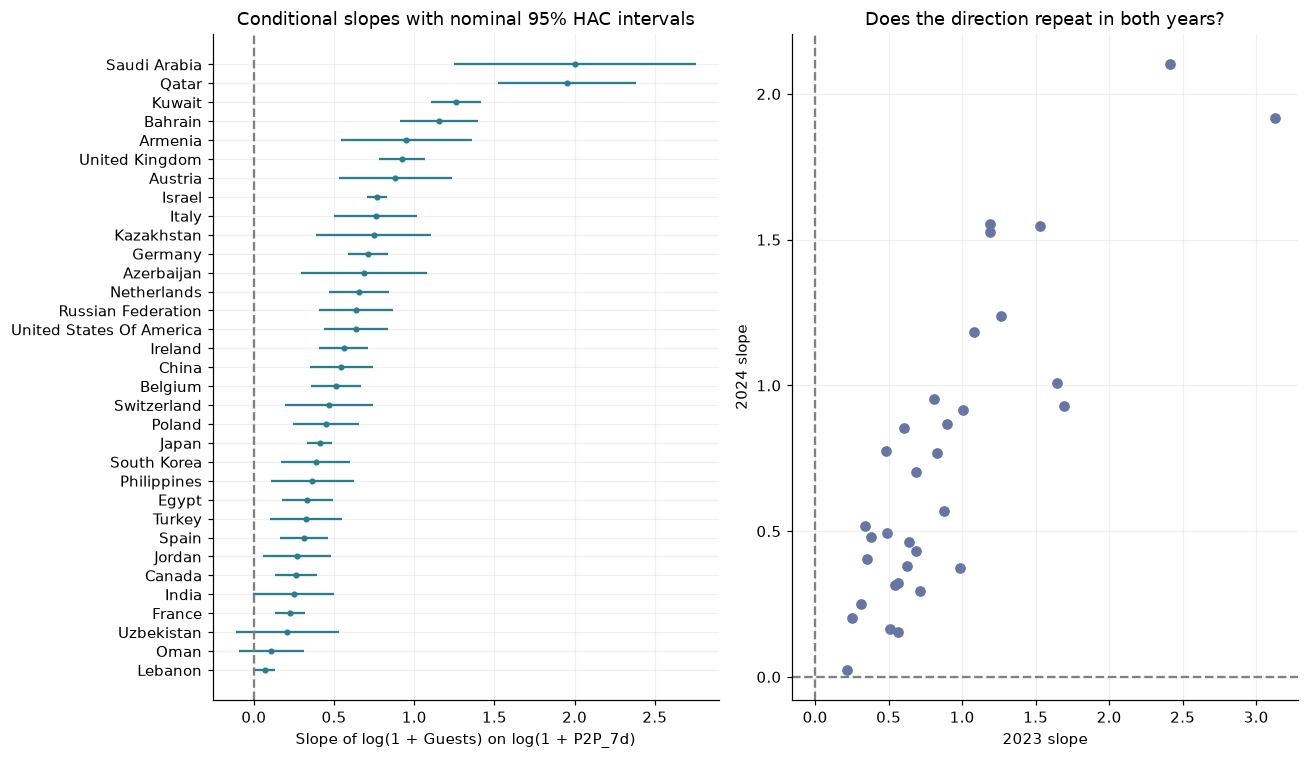

In [12]:
# Descriptive conditional slopes with temporal dependence acknowledged.
# HAC uses up to 28 observation lags; missing hotel days can make this differ slightly from calendar days.
slope_rows=[]
for market,grp in shape.groupby('market'):
    for yr in ['all',2023,2024]:
        a=grp if yr=='all' else grp[grp.year.eq(yr)]
        if len(a)<60: continue
        z=nuisance_matrix(a)
        x=np.column_stack([z,a.lx.to_numpy()])
        fit=sm.OLS(a.ly.to_numpy(),x).fit(cov_type='HAC',cov_kwds={'maxlags':28})
        lo,hi=fit.conf_int()[-1]
        slope_rows.append((market,str(yr),len(a),fit.params[-1],lo,hi))
slopes=pd.DataFrame(slope_rows,columns=['market','period','n','slope_log1p','hac_low','hac_high'])
table('conditional_slopes',slopes,show=False)
slope_stability=slopes[slopes.period.ne('all')].pivot(index='market',columns='period',values='slope_log1p')
slope_stability['positive_both_years']=(slope_stability['2023']>0)&(slope_stability['2024']>0)
table('slope_year_stability',slope_stability.reset_index())
all_slopes=slopes[slopes.period.eq('all')].sort_values('slope_log1p')
fig,axes=plt.subplots(1,2,figsize=(12,7))
axes[0].errorbar(all_slopes.slope_log1p,all_slopes.market.str.title(),
    xerr=[all_slopes.slope_log1p-all_slopes.hac_low,all_slopes.hac_high-all_slopes.slope_log1p],fmt='o',ms=3,color='#287d8e')
axes[0].axvline(0,color='grey',ls='--'); axes[0].set(title='Conditional slopes with nominal 95% HAC intervals',xlabel='Slope of log(1 + Guests) on log(1 + P2P_7d)')
axes[1].scatter(slope_stability['2023'],slope_stability['2024'],color='#6576a5')
axes[1].axhline(0,color='grey',ls='--');axes[1].axvline(0,color='grey',ls='--')
axes[1].set(xlabel='2023 slope',ylabel='2024 slope',title='Does the direction repeat in both years?')
savefig('10_market_slope_stability')

**Interpretation:** these log(1+x) slopes approximate elasticities only away from zero. Their intervals are conditional
on this diagnostic regression and are not corrected for testing many markets. Two years of observational history cannot
separate route supply from every common demand shock. Results may change with calendar controls, travel-channel coverage,
and the origin/nationality assumption. A supported positive association can motivate a simulator shape assumption; it does not prove that assumption.

## 9. Redundancy, frequency, season, and events

More flights and larger aircraft both increase seats. Their separate hotel effects require evidence beyond that identity.
We check whether frequency adds an association after controlling for total seats and calendar/trend within each market-year.
This is an exploratory partial association, not a causal estimate of scheduling convenience.

,feature,seats_7d,flights_7d,p2p_7d,lf_ex_infants_7d,transfer_share_7d,seats_per_flight_7d
0,seats_7d,1.000000,0.948445,0.712006,-0.211184,-0.007539,-0.198650
1,flights_7d,0.948445,1.000000,0.820861,-0.335524,-0.221784,-0.473759
2,p2p_7d,0.712006,0.820861,1.000000,-0.237644,-0.659588,-0.577775
3,lf_ex_infants_7d,-0.211184,-0.335524,-0.237644,1.000000,0.275762,0.488512
4,transfer_share_7d,-0.007539,-0.221784,-0.659588,0.275762,1.000000,0.668312
5,seats_per_flight_7d,-0.198650,-0.473759,-0.577775,0.488512,0.668312,1.000000


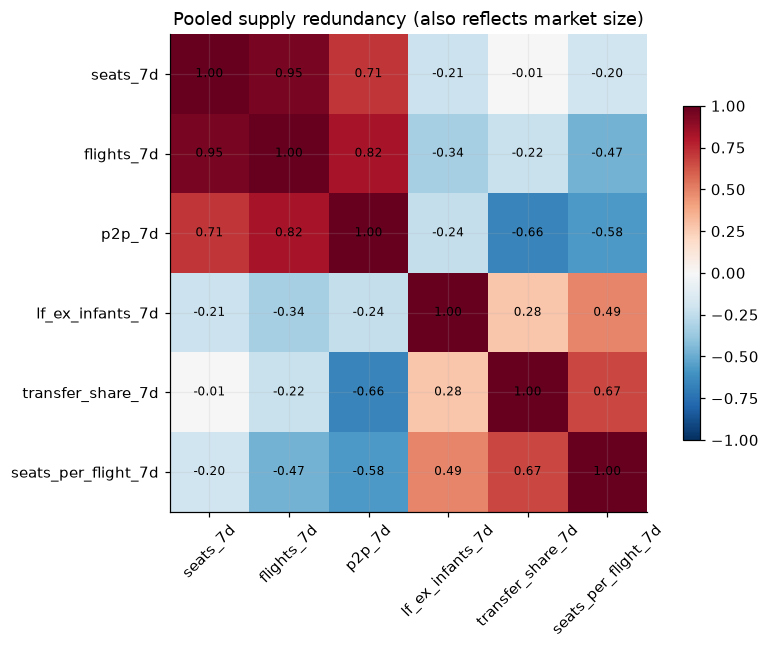

,markets,median_partial_correlation,fraction_positive
year,,,
2023,33,0.039562,0.606061
2024,33,0.002600,0.515152


,event,start,end,source,status
1,ramadan,2023-03-23,2023-04-20,estimate - confirm with DCT,unverified
2,ramadan,2024-03-11,2024-04-09,estimate - confirm with DCT,unverified
6,eid,2023-04-21,2023-04-23,estimate - confirm with DCT,unverified
7,eid,2024-04-10,2024-04-12,estimate - confirm with DCT,unverified
11,eid,2023-06-28,2023-06-30,estimate - confirm with DCT,unverified
12,eid,2024-06-16,2024-06-18,estimate - confirm with DCT,unverified
15,f1_weekend,2023-11-24,2023-11-26,estimate - confirm with DCT,unverified
16,f1_weekend,2024-12-06,2024-12-08,estimate - confirm with DCT,unverified
19,national_day,2023-12-02,2023-12-03,estimate - confirm with DCT,unverified
20,national_day,2024-12-02,2024-12-03,estimate - confirm with DCT,unverified


In [13]:
supply_cols=['seats_7d','flights_7d','p2p_7d','lf_ex_infants_7d','transfer_share_7d','seats_per_flight_7d']
supply=d.loc[d.day_index.ge(27)&d.has_same_name_origin].dropna(subset=supply_cols)
corr=supply[supply_cols].corr(method='spearman')
table('supply_spearman',corr.reset_index().rename(columns={'index':'feature'}))
fig,ax=plt.subplots(figsize=(8,6)); im=ax.imshow(corr,vmin=-1,vmax=1,cmap='RdBu_r')
ax.set(xticks=range(len(supply_cols)),yticks=range(len(supply_cols)),xticklabels=supply_cols,yticklabels=supply_cols,title='Pooled supply redundancy (also reflects market size)')
ax.tick_params(axis='x',rotation=45)
for i in range(len(supply_cols)):
    for j in range(len(supply_cols)): ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8)
fig.colorbar(im,ax=ax,shrink=.7);savefig('11_supply_redundancy')

freq_rows=[]
for (market,yr),a in d.loc[d.day_index.ge(27)&d.has_same_name_origin].groupby(['market','year']):
    a=a.dropna(subset=['Guests','seats_7d','flights_7d'])
    z=np.column_stack([nuisance_matrix(a),np.log1p(a.seats_7d)])
    vals=np.column_stack([np.log1p(a.flights_7d),np.log1p(a.Guests)])
    res=vals-z@np.linalg.lstsq(z,vals,rcond=None)[0]
    freq_rows.append((market,yr,len(a),float(res[:,0].std()),safe_corr(res[:,0],res[:,1])))
freq=pd.DataFrame(freq_rows,columns=['market','year','n','remaining_log_frequency_sd','partial_correlation'])
table('frequency_beyond_seats',freq,show=False)
display(freq.groupby('year').agg(markets=('partial_correlation','count'),median_partial_correlation=('partial_correlation','median'),
    fraction_positive=('partial_correlation',lambda s:(s.dropna()>0).mean())))

events=pd.read_csv(PROJECT/'reference/events.csv',parse_dates=['start','end'])
events=events[(events.end>=START)&(events.start<=END)].copy()
events['status']=np.where(events.source.str.contains('estimate|confirm',case=False,na=True),'unverified','source requires inspection')
table('event_reference_audit',events)
issue('Event evidence',f'{len(events)} reference spans intersect the analysis window; {events.status.eq("unverified").sum()} are explicitly unverified.',
      'Do not attribute demand spikes to these events until dates and affected markets are verified. Two annual repetitions offer limited independent evidence.')

**Why some useful predictors may still be poor simulator inputs.** Hotel check-ins and domestic hotel counts can explain
observed demand, but their future scenario values are not supplied by aviation sliders. Market shares also change together
and sum to one. Adding both an exposure and a derived share to a model requires checking the whole scenario response,
not merely the sign of one model term. `has_same_name_origin` is a coverage flag, not an estimated new-route effect.

## 10. Feature handoff: evidence and implementation implications

The following decision table separates a physical identity, a descriptive association, and an assumption.
For timing features, **supported** means the median adjusted correlation is positive in both years and at least two-thirds
of direct-match markets have a positive adjusted correlation in each year. **Contradicted** means both yearly medians are negative.
All other cases are **inconclusive**. This predeclared rule evaluates the hypothesis of a broadly positive association;
it does not certify monotonicity, significance, or predictive value. Failed hypotheses remain visible.

In [14]:
def timing_status(feature):
    a=timing_summary[timing_summary.feature.eq(feature)]
    if len(a)==2 and a.median_adjusted.gt(0).all() and a.fraction_positive.ge(2/3).all(): return 'supported'
    if len(a)==2 and a.median_adjusted.lt(0).all(): return 'contradicted'
    return 'inconclusive'

features=[]
def feature(name,formula,units,rationale,expected,observed,status,role,availability,missing,limits,sources):
    features.append(dict(variable=name,formula=formula,units=units,domain_rationale=rationale,expected_shape=expected,
        observed_evidence=observed,evidence_status=status,proposed_role=role,scenario_availability=availability,
        missing_behavior=missing,limitations=limits,source_ids=sources))

feature('seat_supply','flights × seats_per_flight','seats','Scheduled capacity is an arithmetic input.',
    'Linear product at fixed gauge/frequency','Decoded frequency is integer-valued; flight aggregation reconciles.',
    'supported','Arithmetic chain','Direct scenario inputs','Reject undefined gauge rather than divide by zero',
    'No separately identified hotel frequency effect.','LOCAL_DICTIONARY;IATA_METRICS')
feature('passenger_to_seat_ratio','PAX / seats, with an infant-excluded alternative','passengers per seat',
    'Distinguish occupied capacity from total people.','Passenger count increases with ratio at fixed seats',
    f'{resolved_infant} overshoots resolve with infant exclusion; {(fl.lf_excluding_infants>1).sum()} remain.',
    'supported','Arithmetic chain, with a documented passenger-count convention','User assumption; infant composition requires its own convention',
    'Unknown when seats are zero','Do not treat all overshoots as errors or distance-weighted industry PLF.','LOCAL_DICTIONARY;IATA_METRICS')
feature('p2p','PAX − transfer − transit','passengers per day','Destination traffic is closer to hotel demand than total throughput.',
    'Nondecreasing demand is a candidate conditional shape assumption','Passenger identity holds; hotel relationship examined below.',
    'supported','Arithmetic chain output','Derived from supply and passenger-mix assumptions','Zero recorded service flagged',
    'Includes non-visitors; nationality and stopover classifications unresolved.','LOCAL_DICTIONARY;UN_IRTS;ETIHAD_STOPOVER')
for f in timing_features:
    a=timing_summary[timing_summary.feature.eq(f)].sort_values('year')
    desc='; '.join(f'{r.year}: median adjusted r={r.median_adjusted:.3f}, positive markets={r.fraction_positive:.0%}' for r in a.itertuples())
    is_weighted='stay_mean' in f
    feature(f,'sum of P2P × geometric retention weights over 28 days' if is_weighted else f'trailing sum over {f.split("_")[1]}',
        'weighted recent passengers' if is_weighted else 'recent passengers',
        'Guests remain after their arrival day.','Nondecreasing conditional demand; flattening is a hypothesis',desc,timing_status(f),
        'Future GAM candidate; choose one exposure representation through later validation',
        'Recompute from scenario flights and prior-day history','First 27 days excluded from comparisons',
        'Assumed stay weights, overlapping windows, no causal identification; cannot recover nationality bridge.',
        'UN_IRTS;KUOK_2024;KOO_2017')
feature('market','hotel nationality; same-name origin is a proxy','category','Markets differ in observed levels and conversion comparisons.',
    'Categorical differences',f'{len(markets)} nationalities; {len(markets)-len(direct)} lack same-name origins.',
    'supported','Future market effects and explicit bridge assumptions','Known market; new-market response remains unmeasured','Unseen market needs a separately validated prior',
    'A nationality label is not a passenger allocation matrix.','UN_IRTS;LOCAL_DICTIONARY')
feature('season','month or day-of-year with year-end continuity','calendar position','Demand may repeat within the year.',
    'Periodic; not monotonic','Two separately normalized annual seasonal profiles are shown.',
    'supported','Future seasonal term; test market differences','Known calendar','No imputation needed',
    'Only two full years; target-derived seasonal index excluded from independent evidence.','DCT_REPORTING')
feature('frequency_beyond_seats','residual log(1 + flights_7d) after capacity/calendar/trend','conditional log frequency',
    'Schedule convenience may matter separately from capacity.','Uncertain',
    '; '.join(f'{yr}: median partial r={a.partial_correlation.median():.3f}' for yr,a in freq.groupby('year')),
    'inconclusive','Keep as arithmetic lever; defer separate GAM term','Frequency is adjustable','Undefined if no useful conditional variation',
    'Not an identified convenience effect; gauge and carrier mix can confound.','KOO_2017')
feature('hotel_arrivals_per_origin_p2p','monthly hotel arrivals / same-name origin P2P','cross-dataset ratio',
    'Exposes mismatch in populations.','No valid probability bound',f'{(valid_conv>1).sum()} complete months exceed one.',
    'contradicted','Descriptive only; hypothesis of a directly measured capture probability fails',
    'Hotel arrivals are not known for new aviation scenarios','Require complete month and positive denominator',
    'Do not clip to [0,1] or use a target-linked ratio as an independent explanatory feature.','UN_IRTS;LOCAL_DICTIONARY')
feature('guest_days_per_arrival','sum(Guests) / sum(New Arrivals), complete months','reported guest-days per arrival',
    'Connects arrival flow with accumulated presence.','Positive; varying by market and season','Period ratios and same-day sensitivity are tabulated.',
    'inconclusive','Descriptive stay proxy; confirm semantics before using as length of stay','Scenario stay is an assumption, not an observed future value',
    'Require complete observations and positive arrivals','Boundary stays and same-day overlap unresolved.','UN_IRTS;LOCAL_DICTIONARY')
feature('events','verified event dates and affected market','indicator','Events may change demand temporarily.',
    'Event-specific; not automatically positive',f'{events.status.eq("unverified").sum()} current spans explicitly unverified.',
    'inconclusive','Defer until dates and market applicability are sourced','Known future dates only after verification','Do not label unsourced dates as verified',
    'No estimated event effect in this notebook.','DCT_REPORTING')
feature('domestic_hotel_demand','domestic Guests and New Arrivals','daily people/guest-days','Describes a separate demand stream.',
    'Seasonal; no imposed aviation response','Separate seasonal profiles shown.',
    'supported','Separate domestic component; historical context only in this analysis','Future domestic demand needs its own forecast or assumption',
    'Never substitute unknown domestic Guests with zero','Domestic guest target is also absent from test.','LOCAL_DICTIONARY')
feature('origin_share_7d','origin P2P_7d / total P2P_7d','share','Describes recorded traffic mix.',
    'Compositional; no standalone monotonic assumption','Existing market_share_12m matches this 7-day quantity.',
    'inconclusive','Descriptive; avoid duplicate exposure terms until scenario behavior is checked','Recomputed jointly for all origins',
    'Undefined when total P2P is zero','One origin changing affects other shares; name accurately.','LOCAL_DICTIONARY')
feature_evidence=table('feature_evidence',pd.DataFrame(features),show=False)
display(feature_evidence[['variable','evidence_status','proposed_role','observed_evidence']])

,variable,evidence_status,proposed_role,observed_evidence
0,seat_supply,supported,Arithmetic chain,Decoded frequency is integer-valued; flight aggregation reconciles.
1,passenger_to_seat_ratio,supported,"Arithmetic chain, with a documented passenger-count convention",3257 overshoots resolve with infant exclusion; 1929 remain.
2,p2p,supported,Arithmetic chain output,Passenger identity holds; hotel relationship examined below.
3,p2p_1d,supported,Future GAM candidate; choose one exposure representation through later validation,"2023: median adjusted r=0.202, positive markets=100%; 2024: median adjusted r=0.164, positive ma..."
4,p2p_3d,supported,Future GAM candidate; choose one exposure representation through later validation,"2023: median adjusted r=0.377, positive markets=100%; 2024: median adjusted r=0.331, positive ma..."
5,p2p_7d,supported,Future GAM candidate; choose one exposure representation through later validation,"2023: median adjusted r=0.444, positive markets=100%; 2024: median adjusted r=0.453, positive ma..."
6,p2p_14d,supported,Future GAM candidate; choose one exposure representation through later validation,"2023: median adjusted r=0.396, positive markets=100%; 2024: median adjusted r=0.335, positive ma..."
7,p2p_28d,supported,Future GAM candidate; choose one exposure representation through later validation,"2023: median adjusted r=0.266, positive markets=97%; 2024: median adjusted r=0.255, positive mar..."
8,p2p_stay_mean_2,supported,Future GAM candidate; choose one exposure representation through later validation,"2023: median adjusted r=0.362, positive markets=100%; 2024: median adjusted r=0.323, positive ma..."
9,p2p_stay_mean_4,supported,Future GAM candidate; choose one exposure representation through later validation,"2023: median adjusted r=0.471, positive markets=100%; 2024: median adjusted r=0.409, positive ma..."


## 11. Reproducibility checks and conclusions

The checks below protect the analysis boundary and data flow. They do not certify the model assumptions.
No supplied data or reference file is overwritten. Diagnostic regressions are used for conditional plots only;
there is no fitted forecasting model artifact or claimed validation score.

In [15]:
# Hand-computable rolling and retention checks, including a future perturbation.
toy=np.array([2.,0.,3.,1.,0.,0.])
check('Trailing sums include current and past only',np.allclose(pd.Series(toy).rolling(3).sum().dropna(),[5,4,4,1]))
w=np.array([1.,.5,.25])
conv_toy=np.convolve(toy,w,'full')[:len(toy)]
check('Weighted exposure agrees with manual calculation',np.allclose(conv_toy[:4],[2,1,3.5,2.5]))
changed=toy.copy();changed[4]=1000
check('Future passenger changes cannot alter earlier weighted exposure',np.allclose(np.convolve(changed,w,'full')[:4],conv_toy[:4]))
for m,a in d.groupby('market'):
    check(f'Trailing 7-day source reconciliation: {m}',np.allclose(a.p2p.rolling(7,min_periods=7).sum(),a.p2p_7d,equal_nan=True))
check('Analysis target-derived history features absent',not {'season_index','capture_rate_hist','elasticity_tier','stay_length_hist'}.intersection(d.columns))
check('No holdout rows in diagnostic tables',d.Date.between(START,END).all() and set(timing_results.year)=={2023,2024})
check('Zero denominator produces unknown, not infinity',np.isnan(ratio(pd.Series([1.]),pd.Series([0.])).iloc[0]))
check('No infinity in generated analysis variables',not np.isinf(d.select_dtypes(include='number').to_numpy()).any())
check('All feature evidence has provenance and limitations',feature_evidence[['source_ids','limitations']].notna().all().all())
check('Input files unchanged',all(hashlib.sha256((PROJECT/p).read_bytes()).hexdigest()==digest for p,digest in input_hashes.items()))
table('data_issues',pd.DataFrame(ISSUES))
table('verification',pd.DataFrame(CHECKS),show=False)
packages=['pandas','numpy','scipy','statsmodels','matplotlib','pyarrow','openpyxl','nbformat','nbclient','ipykernel','jupyterlab']
manifest={'run_utc':datetime.now(timezone.utc).isoformat(),'python':platform.python_version(),
    'analysis_start':str(START.date()),'analysis_end':str(END.date()),'research_reviewed_on':RESEARCH_DATE,
    'seed':SEED,'inputs_sha256':input_hashes,'versions':{p:metadata.version(p) for p in packages},
    'check_count':len(CHECKS),'all_checks_passed':all(x['passed'] for x in CHECKS)}
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
positive_both=int(slope_stability.positive_both_years.sum())
best_by_year=timing_summary.loc[timing_summary.groupby('year').median_adjusted.idxmax(),['year','feature','median_adjusted']]
best_text='; '.join(f'{r.year}: {r.feature} (median adjusted correlation {r.median_adjusted:.3f})' for r in best_by_year.itertuples())
supported=feature_evidence[feature_evidence.variable.isin(timing_features)&feature_evidence.evidence_status.eq('supported')].variable.tolist()
display(Markdown(f'''
### What this run establishes

- **Measurement:** excluding infants resolves {resolved_infant:,} load-factor overshoots, but {(fl.lf_excluding_infants>1).sum():,} remain. Historical clipping needs a stated convention.
- **Target coverage:** {len(DATES)*len(markets)-len(hotel):,} nationality-days are absent in the source. The previous panel supplies target values on {target_rewrites.sum():,} of them; this analysis leaves them unknown.
- **Bridge:** {no_origin_share:.1%} of observed international guest-days belong to nationalities without a same-name flight origin. Their demand cannot be explained by an identity bridge alone.
- **Conversion:** {(valid_conv>1).sum()} of {len(valid_conv)} complete origin-month comparisons exceed one hotel check-in per recorded same-name P2P passenger. This ratio is not an identified capture probability.
- **Conditional consistency:** {positive_both}/{len(slope_stability)} direct-match markets have positive seven-day conditional slopes in both years. This is an association check, not a monotonicity or causality guarantee.
- **Timing:** the largest median adjusted correlations are {best_text}. Selection still requires later validation; overlapping windows are not independent evidence.
- **Positive-association screen:** {', '.join(supported) if supported else 'No timing feature passes the predeclared broad-positive-association screen.'}
- **Reproducibility:** all {len(CHECKS)} assertions passed. Tables, figures, and the input/environment manifest are under `reports/domain_analysis/`.

### Next modeling decisions

Use the arithmetic supply chain and test a small set of recent-passenger representations in a later GAM notebook.
Allow market and seasonal differences, and inspect the response of the whole scenario calculation.
Confirm the meaning of `Guests` and same-day overlaps, investigate remaining load-factor discrepancies,
and document a bridge/new-route assumption before claiming an aviation-to-overnight-demand conversion.
Do not force all markets to follow a positive curve solely because the pooled relationship looks positive.
'''))

,issue,finding,implication
0,Dictionary versus extract,Dictionary describes monthly flights and a Guests field in test; observed files differ.,Use observed grain/schema; retain dictionary as semantic guidance with documented conflicts.
1,Load factors above 100%,"3,257 cases resolve when infants are excluded; 1,929 remain.",Keep both ratios and anomaly flags. Do not silently clip historical counts; seek clarification o...
2,Guests versus guest nights,"Dictionary describes daily total guests and separately same-day guests, without defining whether...",Use Guests (daily reported target) and guest-days (sum of daily target); do not silently relabel...
3,Blank same-day counts,"19,302 international rows have unknown same-day counts.","Preserve unknown values. Guests minus known same-day counts is a sensitivity calculation, not a ..."
4,Missing international hotel rows,33,Leave target and arrivals missing; do not assign zero from small neighboring values.
5,Zero recorded service convention,9644,"Zero recorded flights is not proof of complete traffic coverage, nor proof of zero hotel demand."
6,Existing panel target imputation,29,Analysis preserves raw missing target observations; no edits to the cleaning notebook or existin...
7,Misnamed market_share_12m,True,It is a 7-day origin share; use an accurately named recomputation.
8,Unidentified country bridge,7.6% of observed international guest-days belong to the 12 nationalities without a same-name ori...,"These are background-demand examples, not zero-demand markets. New-route response needs separate..."
9,Conversion ratio exceeds probability bounds,196 / 787 complete origin-months exceed one.,"Do not clamp or call this an individual capture probability; departure country, nationality, and..."



### What this run establishes

- **Measurement:** excluding infants resolves 3,257 load-factor overshoots, but 1,929 remain. Historical clipping needs a stated convention.
- **Target coverage:** 33 nationality-days are absent in the source. The previous panel supplies target values on 29 of them; this analysis leaves them unknown.
- **Bridge:** 7.6% of observed international guest-days belong to nationalities without a same-name flight origin. Their demand cannot be explained by an identity bridge alone.
- **Conversion:** 196 of 787 complete origin-month comparisons exceed one hotel check-in per recorded same-name P2P passenger. This ratio is not an identified capture probability.
- **Conditional consistency:** 33/33 direct-match markets have positive seven-day conditional slopes in both years. This is an association check, not a monotonicity or causality guarantee.
- **Timing:** the largest median adjusted correlations are 2023: p2p_stay_mean_4 (median adjusted correlation 0.471); 2024: p2p_7d (median adjusted correlation 0.453). Selection still requires later validation; overlapping windows are not independent evidence.
- **Positive-association screen:** p2p_1d, p2p_3d, p2p_7d, p2p_14d, p2p_28d, p2p_stay_mean_2, p2p_stay_mean_4, p2p_stay_mean_7
- **Reproducibility:** all 75 assertions passed. Tables, figures, and the input/environment manifest are under `reports/domain_analysis/`.

### Next modeling decisions

Use the arithmetic supply chain and test a small set of recent-passenger representations in a later GAM notebook.
Allow market and seasonal differences, and inspect the response of the whole scenario calculation.
Confirm the meaning of `Guests` and same-day overlaps, investigate remaining load-factor discrepancies,
and document a bridge/new-route assumption before claiming an aviation-to-overnight-demand conversion.
Do not force all markets to follow a positive curve solely because the pooled relationship looks positive.
